In [1]:
import sys
sys.path.append("..")
from data_reader import DataReader
from processed_data_storage import ProcessedDataStroage
from preprocess import Preprocessor
import numpy as np
import tensorflow as tf
import mne
data_reader = DataReader()
subjects_range = range(1, 3)

data_reader = DataReader()
processed_data_storage = ProcessedDataStroage()
category_per_epochs_all_subs = []

for sub in subjects_range:
    subject = sub + 100
    subject = str(subject)
    raw, channels, events = data_reader.read_data(
        subject=str(subject),
    )

    preprocessor = Preprocessor(raw, 2)
    del raw

    preprocessor.run_pipeline(use_filter=True, use_ica=False, use_autoreject=False)

    epochs_train, epochs_test = preprocessor.split_train_test()

    X_train, X_test = preprocessor.scale(epochs_train.get_data(), epochs_test.get_data())

    labels_train, category_per_epoch = preprocessor.create_labels_for_epochs(epochs_train)    # Form (1638, 120)
    labels_test, _ = preprocessor.create_labels_for_epochs(epochs_test)      # Form (410, 120)
    category_per_epochs_all_subs.append(category_per_epoch)
    processed_data_storage.save_subject(subject, {"X_train": X_train, "X_test": X_test, "labels_train": labels_train, "labels_test": labels_test})

    evoked_face = epochs_train["face"].average()
    evoked_animal = epochs_train["animal"].average()
    mne.viz.plot_compare_evokeds({"face": evoked_face, "animal": evoked_animal}, picks="P8")
    mne.viz.plot_compare_evokeds({"face": evoked_face, "animal": evoked_animal}, picks="PO8")
    mne.viz.plot_compare_evokeds({"face": evoked_face, "animal": evoked_animal}, picks="P7")
    mne.viz.plot_compare_evokeds({"face": evoked_face, "animal": evoked_animal}, picks="PO7")


None


I0000 00:00:1795168271.400003   24612 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795168271.442487   24612 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795168272.385516   24612 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Arbeitsverzeichnis: /home/bened/bachelor-thesis/notebooks/BunDLe-Net/notebooks
Datenverzeichnis: /home/bened/bachelor-thesis/data/raw/ds005363-download
Arbeitsverzeichnis: /home/bened/bachelor-thesis/notebooks/BunDLe-Net/notebooks
Datenverzeichnis: /home/bened/bachelor-thesis/data/raw/ds005363-download
Arbeitsverzeichnis: /home/bened/bachelor-thesis/notebooks/BunDLe-Net/notebooks
Datenverzeichnis: /home/bened/bachelor-thesis/data/raw/ds005363-download
Lese BrainVision-Aufnahme ein: /home/bened/bachelor-thesis/data/raw/ds005363-download/sub-101/ses-01/eeg/sub-101_ses-01_task-objrecog_eeg.vhdr


TypeError: Preprocessor.__init__() takes from 1 to 2 positional arguments but 3 were given

In [1]:
print(epochs_train.times)

NameError: name 'epochs_train' is not defined

In [3]:
X_train = []
X_test = []
labels_train = []
labels_test = []

for sub in subjects_range:
    subject = sub + 100
    values = processed_data_storage.load_subject(subject)
    X_train.append(values[0])
    X_test.append(values[1])
    labels_train.append(values[2])
    labels_test.append(values[3])

X_train = np.concatenate(X_train, axis=0)
X_test = np.concatenate(X_test, axis=0)
labels_train = np.concatenate(labels_train, axis=0)
labels_test = np.concatenate(labels_test, axis=0)
category_per_epochs_all_subs = np.concatenate(category_per_epochs_all_subs, axis=0)
print(category_per_epochs_all_subs.shape)
number_of_epochs, number_of_channels, number_of_time_points = X_train.shape
print(f"X_train shape: {X_train.shape}")
print(f"Number of epochs: {number_of_epochs}")
print(f"Number of channels: {number_of_channels}")

# Alle Fensterpaare der Trainingsdaten (darauf wird trainiert)
epoch_numbers, start_time_points = preprocessor.list_all_window_pairs(
    number_of_epochs, number_of_time_points, preprocessor.WINDOW_LENGTH
)

# Alle Fensterpaare der Testdaten (werden nur ausgewertet, nie trainiert)
number_of_test_epochs = X_test.shape[0]
number_of_test_time_points = X_test.shape[2]
test_epoch_numbers, test_start_time_points = preprocessor.list_all_window_pairs(
    number_of_test_epochs, number_of_test_time_points, preprocessor.WINDOW_LENGTH
)

# Feste Zufallsauswahl an Trainingsfenstern, genauso viele wie Testfenster.
# Auf dieser Auswahl messen wir nach jeder Trainingsepoche Loss und Genauigkeit
# auf genau dieselbe Art wie auf den Testdaten.
random_generator = np.random.default_rng(11)
train_subset_indices = random_generator.choice(
    len(epoch_numbers), size=len(test_epoch_numbers), replace=False
)
train_subset_epoch_numbers = epoch_numbers[train_subset_indices]
train_subset_start_time_points = start_time_points[train_subset_indices]

print(f"Trainingsfenster: {len(epoch_numbers)}, davon ausgewertet: {len(train_subset_epoch_numbers)}")
print(f"Testfenster: {len(test_epoch_numbers)}")

# Zufallswert (reines Raten) als Vergleichslinie.
# Das Ziel eines Fensterpaares ist das Label am Index start + WINDOW_LENGTH,
# also frühestens am Index WINDOW_LENGTH. Davor liegende Labels kommen als Ziel nie vor.
target_labels_that_can_occur = labels_train[:, preprocessor.WINDOW_LENGTH:]
target_categories = np.unique(target_labels_that_can_occur)
number_of_target_categories = len(target_categories)
chance_loss = np.log(number_of_target_categories)
chance_accuracy = 1 / number_of_target_categories
print(f"Kategorien, die als Ziel vorkommen: {target_categories}")
print(f"Raten ergibt Loss ln({number_of_target_categories}) = {chance_loss:.3f} und Genauigkeit {chance_accuracy:.2f}")

(1638,)
X_train shape: (1638, 64, 120)
Number of epochs: 1638
Number of channels: 64
Trainingsfenster: 171990, davon ausgewertet: 43050
Testfenster: 43050
Kategorien, die als Ziel vorkommen: [0. 1. 2.]
Raten ergibt Loss ln(3) = 1.099 und Genauigkeit 0.33


Spatio-temporal: 78.4%
Computing rank from data with rank=None
    Using tolerance 30 (2.2e-16 eps * 64 dim * 2.1e+15  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=1 covariance using EMPIRICAL
Done.
Estimating class=2 covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 30 (2.2e-16 eps * 64 dim * 2.1e+15  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=1 covariance using EMPIRICAL
Done.
Estimating class=2 covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 30 (2.2e-16 eps * 64 dim * 2.1e+15  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=1 covariance u

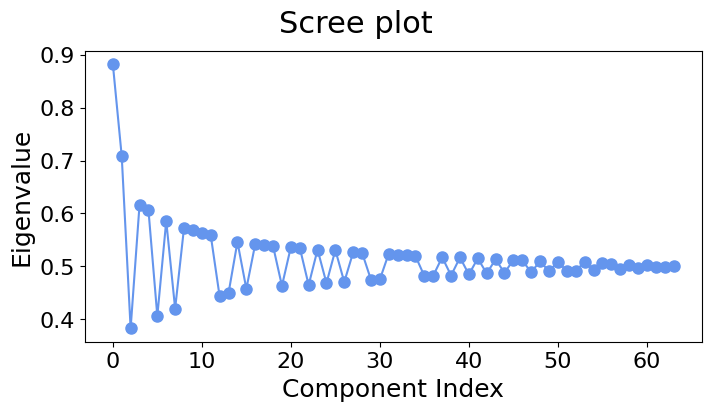

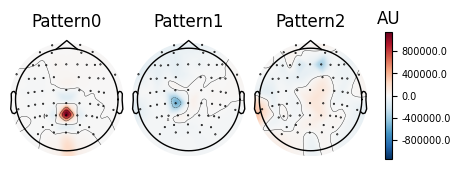

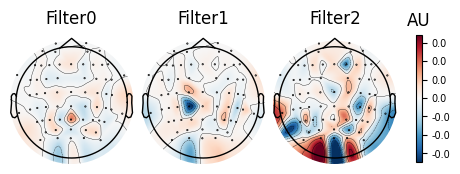

/home/bened/bachelor-thesis/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| Fitting SlidingEstimator : 120/120 [00:00<00:00,  150.14it/s]
100%|██████████| Fitting SlidingEstimator : 120/120 [00:00<00:00,  152.39it/s]
100%|██████████| Fitting SlidingEstimator : 120/120 [00:00<00:00,  144.27it/s]
100%|██████████| Fitting SlidingEstimator : 120/120 [00:01<00:00,   87.45it/s]


No projector specified for this dataset. Please consider the method self.add_proj.


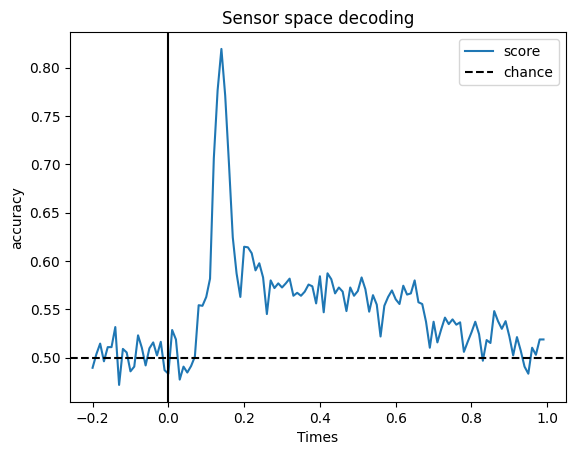

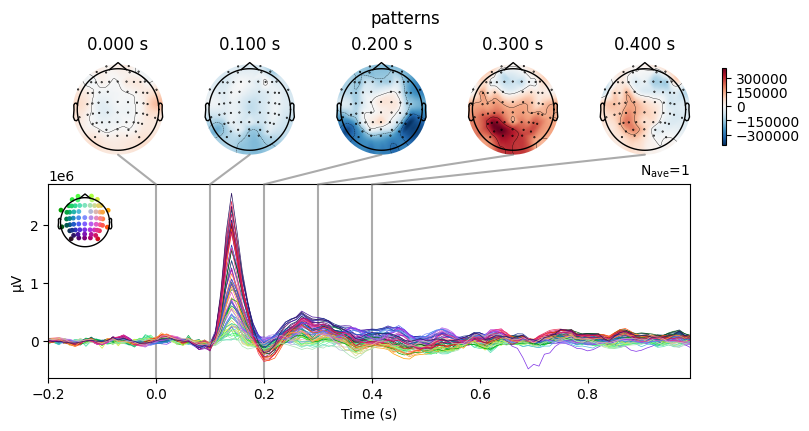

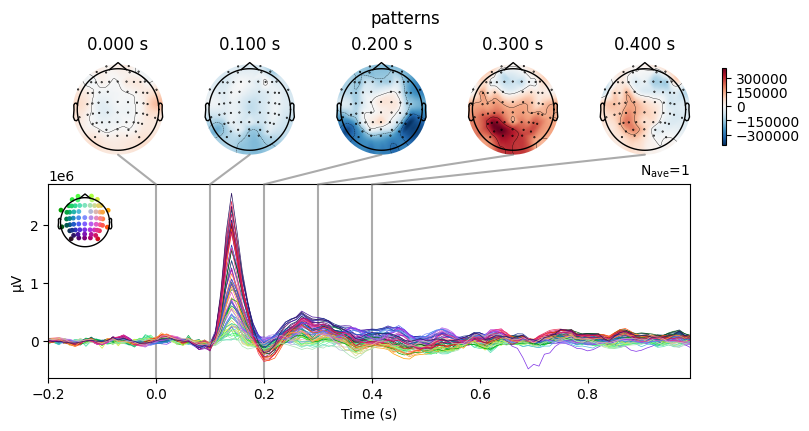

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from mne.decoding import (
    CSP,
    GeneralizingEstimator,
    LinearModel,
    Scaler,
    SlidingEstimator,
    Vectorizer,
    cross_val_multiscore,
    get_coef,
    get_spatial_filter_from_estimator,
)
import matplotlib.pyplot as plt


# Uses all MEG sensors and time points as separate classification
# features, so the resulting filters used are spatio-temporal
clf = make_pipeline(
    Vectorizer(),
    # liblinear is faster than lbfgs
    LogisticRegression(solver="liblinear", random_state=31),
)

scores = cross_val_multiscore(clf, X_train, y=category_per_epochs_all_subs, cv=5, n_jobs=None)

# Mean scores across cross-validation splits
score = np.mean(scores, axis=0)
print(f"Spatio-temporal: {100 * score:0.1f}%")

csp = CSP(n_components=3, norm_trace=False)
clf_csp = make_pipeline(
    csp, LinearModel(LogisticRegression(solver="liblinear", random_state=37))
)
scores = cross_val_multiscore(clf_csp, X_train, category_per_epochs_all_subs, cv=5, n_jobs=None)
print(f"CSP: {100 * scores.mean():0.1f}%")

csp.fit(X_train, category_per_epochs_all_subs)
spf = get_spatial_filter_from_estimator(csp, info=epochs_train.info)
spf.plot_scree()
spf.plot_patterns(components=[0, 1, 2])
spf.plot_filters(components=[0, 1, 2], scalings=1e-9)

clf = make_pipeline(
    LogisticRegression(solver="liblinear", random_state=41)
)
time_decod = SlidingEstimator(clf, n_jobs=None, scoring="accuracy", verbose=True)
# here we use cv=3 just for speed
scores = cross_val_multiscore(time_decod, X_train, category_per_epochs_all_subs, cv=3, n_jobs=None)

# Mean scores across cross-validation splits
scores = np.mean(scores, axis=0)

# Plot
fig, ax = plt.subplots()
ax.plot(epochs_train.times, scores, label="score")
ax.axhline(0.5, color="k", linestyle="--", label="chance")
ax.set_xlabel("Times")
ax.set_ylabel("accuracy")  # Area Under the Curve
ax.legend()
ax.axvline(0.0, color="k", linestyle="-")
ax.set_title("Sensor space decoding")

clf = make_pipeline(
    LinearModel(LogisticRegression(solver="liblinear", random_state=43)),
)
time_decod = SlidingEstimator(clf, n_jobs=None, scoring="accuracy", verbose=True)
time_decod.fit(X_train, category_per_epochs_all_subs)

coef = get_coef(time_decod, "patterns_", inverse_transform=True)
evoked_time_gen = mne.EvokedArray(coef, epochs_train.info, tmin=epochs_train.times[0])
joint_kwargs = dict(ts_args=dict(time_unit="s"), topomap_args=dict(time_unit="s"))
evoked_time_gen.plot_joint(
    times=np.arange(0.0, 0.500, 0.100), title="patterns", **joint_kwargs
)